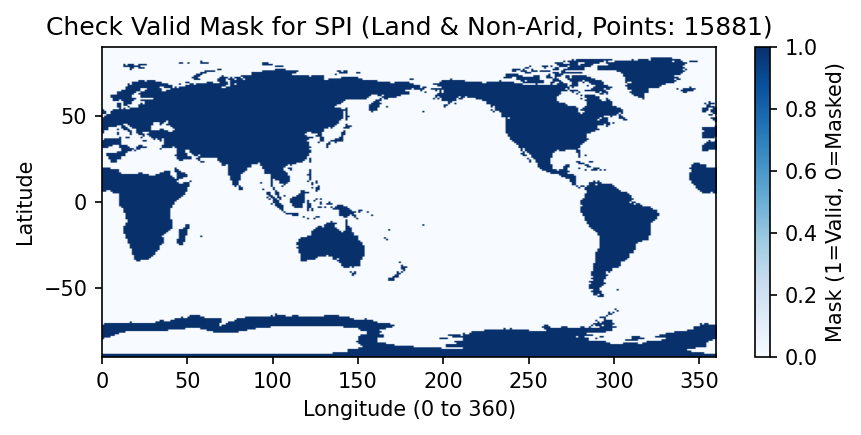

In [11]:
# SPI(PR Z-score)마스킹 격자 확인용 피규어

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import xarray as xr
from scipy.stats import norm
import seaborn as sns
from global_land_mask import globe

ds_ssp = xr.open_dataset('PR_mean.nc', decode_times=False)

ssp_mean_grid = None
for v in ds_ssp.data_vars:
    arr = ds_ssp[v].squeeze()
    if arr.ndim == 2 and arr.shape == (192, 288):
        ssp_mean_grid = arr.values
        break
if ssp_mean_grid is None:
    ssp_mean_grid = ds_ssp[list(ds_ssp.data_vars)[0]].squeeze().values

lats = np.clip(ds_ssp['lat'].values, -90.0, 90.0)
lons = ds_ssp['lon'].values

lons_180 = np.where(lons > 180, lons - 360, lons)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)


is_land = globe.is_land(lat_grid, lon_grid)

# 강수량이 극단적으로 적은 사막을 제외하기 위한 조건
mean_val = np.nanmean(ssp_mean_grid)
arid_threshold = 2.315e-6 if mean_val > 1e-6 else 2.315e-9
is_not_arid = (ssp_mean_grid >= arid_threshold)

valid_mask = is_land & is_not_arid

plt.figure(figsize=(6, 3), dpi=150)
plt.imshow(valid_mask, origin='lower', extent=[0, 360, -90, 90], cmap='Blues', aspect='auto')
plt.title(f"Check Valid Mask for SPI (Land & Non-Arid, Points: {np.sum(valid_mask)})")
plt.xlabel("Longitude (0 to 360)")
plt.ylabel("Latitude")
plt.colorbar(label="Mask (1=Valid, 0=Masked)")
plt.tight_layout()
plt.savefig('masking check', dpi=300)
plt.show()

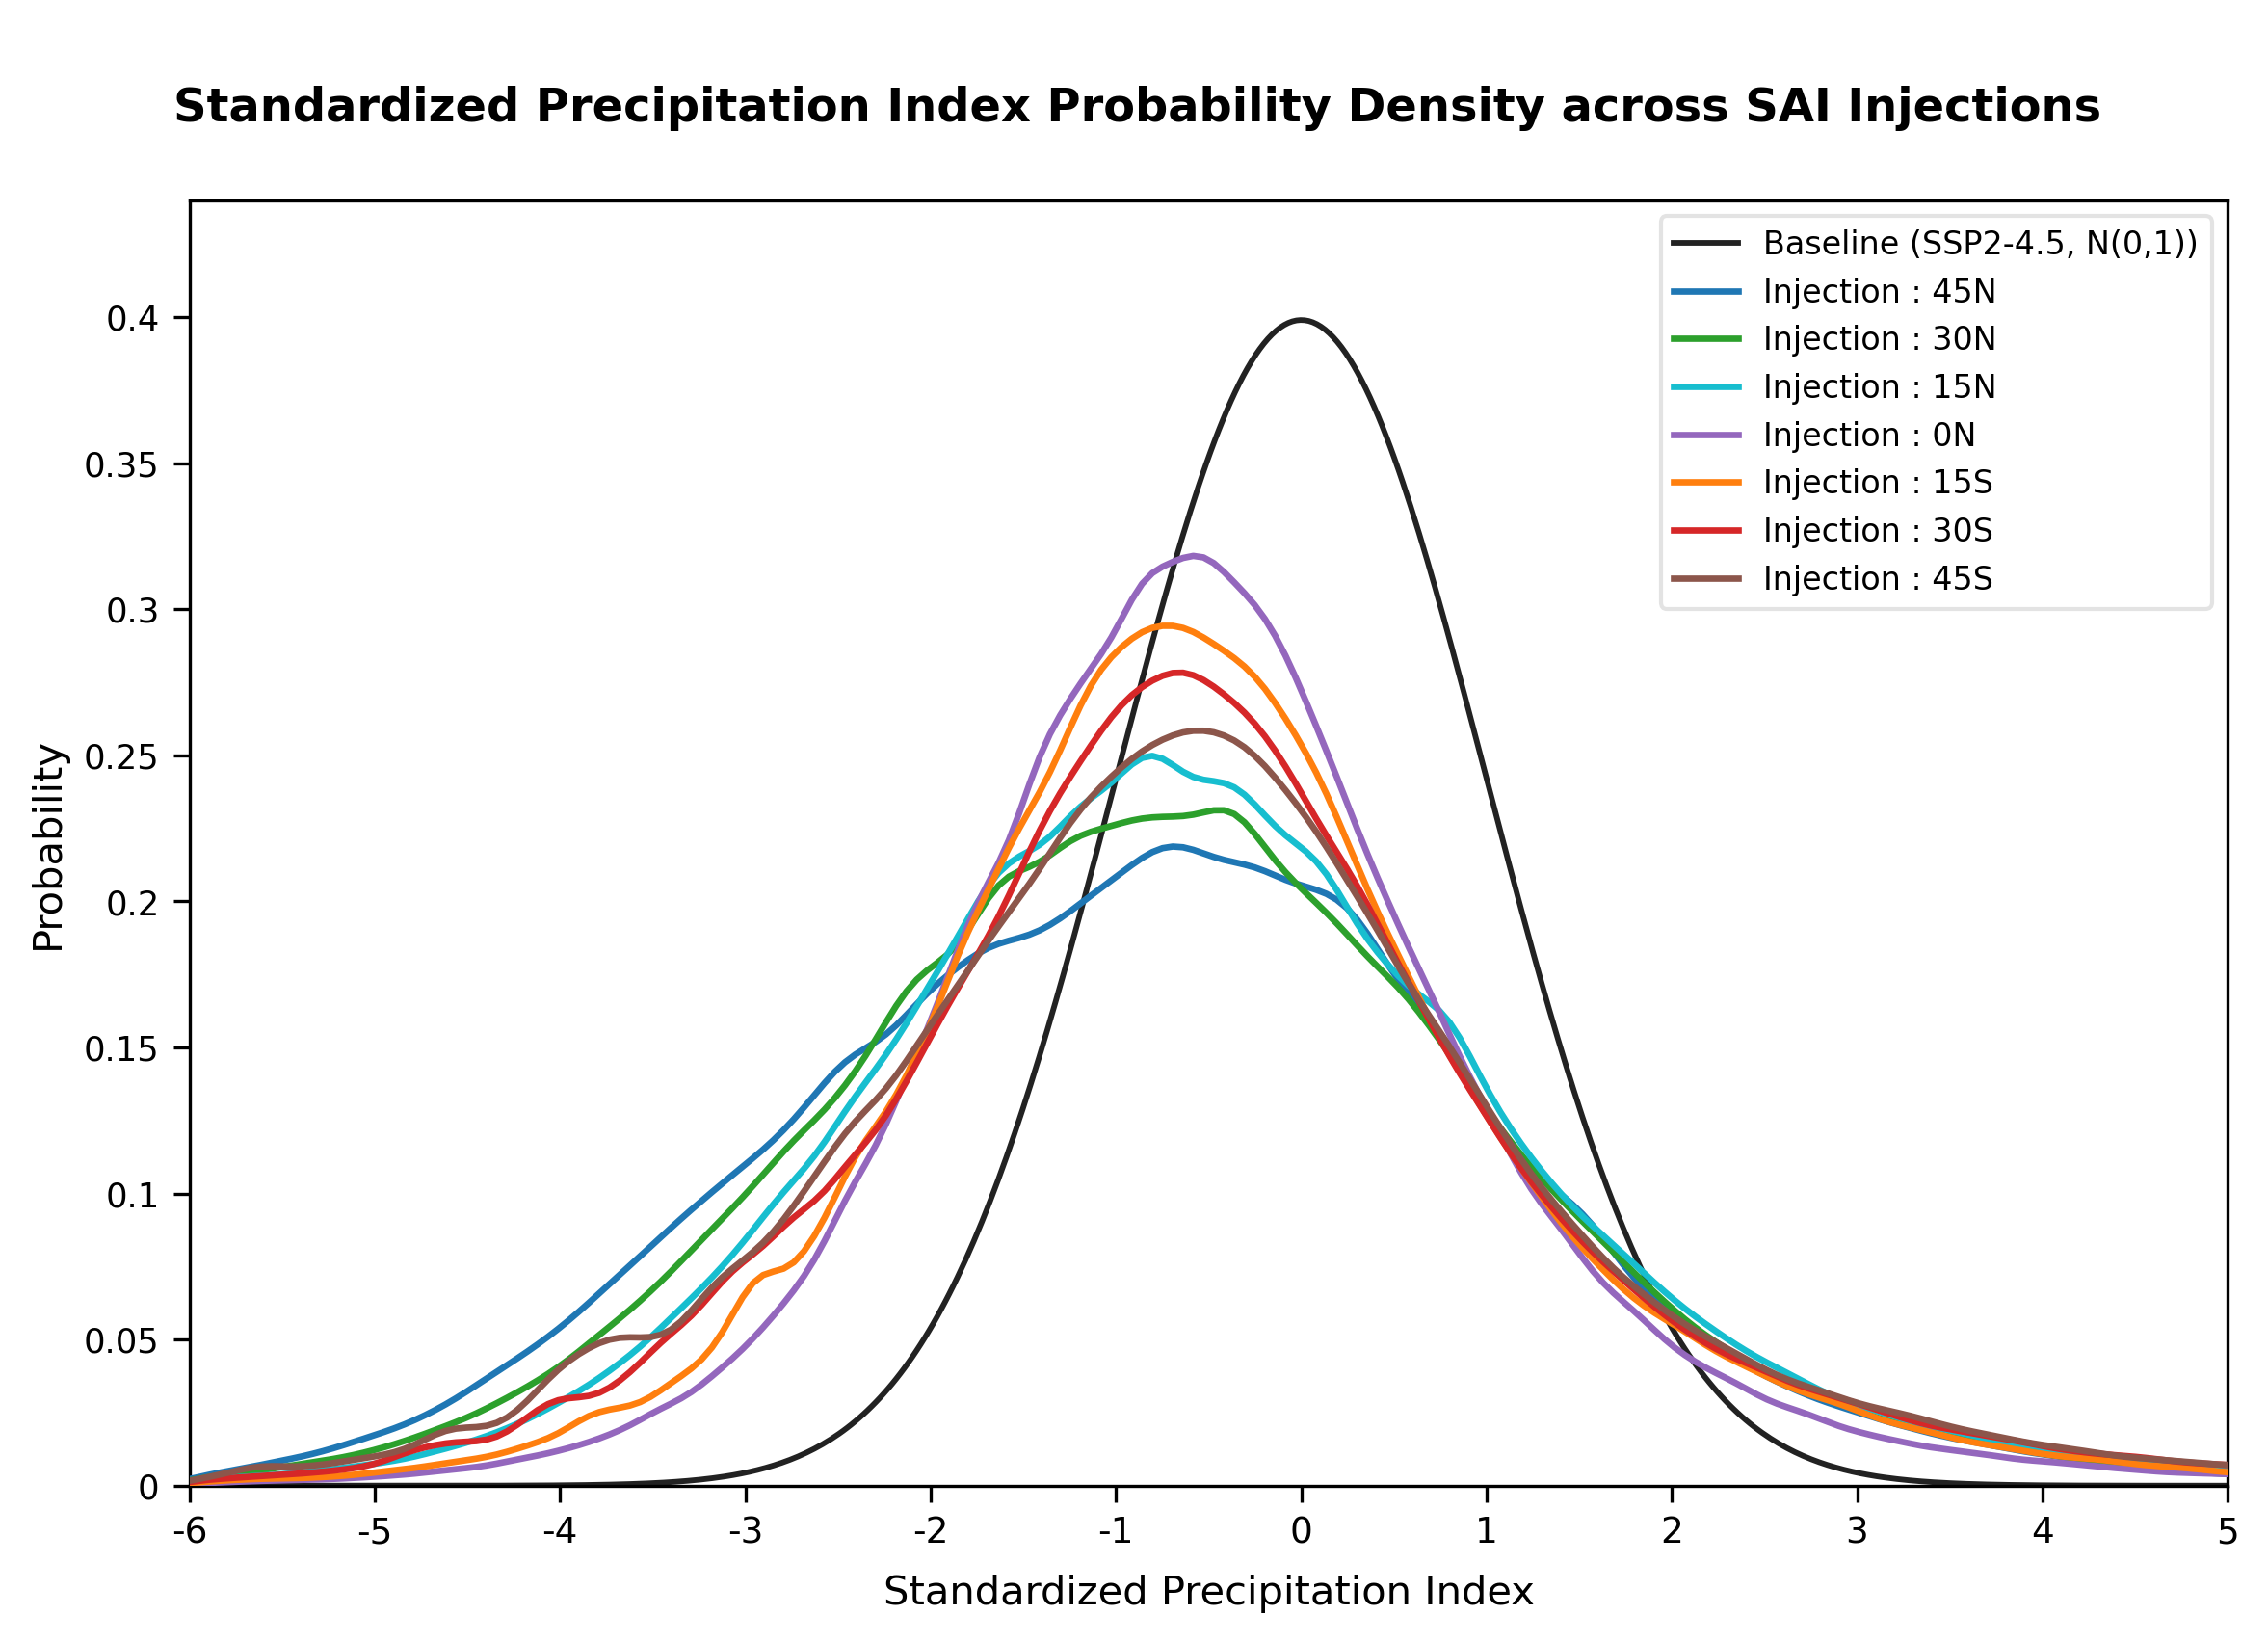

In [8]:
# SPI PDF figure

from global_land_mask import globe
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import seaborn as sns
import xarray as xr

ds_ssp = xr.open_dataset('PR_mean.nc', decode_times=False)

ssp_mean_grid = None
for v in ds_ssp.data_vars:
  arr = ds_ssp[v].squeeze()
  if arr.ndim == 2 and arr.shape == (192, 288):
    ssp_mean_grid = arr.values
    break

if ssp_mean_grid is None:
  candidate = [k for k in ds_ssp.data_vars if 'PR' in k.upper()][0]
  ssp_mean_grid = ds_ssp[candidate].squeeze().values

lons = ds_ssp['lon'].values
lats = np.clip(ds_ssp['lat'].values, -90.0, 90.0)

lons_180 = np.clip(np.where(lons > 180, lons - 360, lons), -180.0, 180.0)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)

# 육상 마스크 & 사막 제외 마스크
is_land = globe.is_land(lat_grid, lon_grid)
mean_val = np.nanmean(ssp_mean_grid)
arid_threshold = 2.315e-6 if mean_val > 1e-6 else 2.315e-9
is_not_arid = ssp_mean_grid >= arid_threshold
valid_mask = is_land & is_not_arid

fig, (ax_bar, ax) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8.2, 5.6),
    dpi=300,
    gridspec_kw={'height_ratios': [0.10, 0.90], 'hspace': 0.04},
)

x_min, x_max = -6.0, 5.0

ax_bar.set_xlim(x_min, x_max)
ax_bar.set_ylim(0, 1)
ax_bar.axis('off')

# 범례
x_axis = np.linspace(x_min, x_max, 500)
ax.plot(
    x_axis,
    norm.pdf(x_axis, 0, 1),
    color='#222222',
    linestyle='-',
    linewidth=1.4,
    label='Baseline (SSP2-4.5, N(0,1))',
    zorder=2,
)

scenarios = {
    '45N': 'PR_z-score_45N.nc',
    '30N': 'PR_z-score_30N.nc',
    '15N': 'PR_z-score_15N.nc',
    '0N': 'PR_z-score_0N.nc',
    '15S': 'PR_z-score_15S.nc',
    '30S': 'PR_z-score_30S.nc',
    '45S': 'PR_z-score_45S.nc',
}

palette = {
    '45N': '#1F77B4',
    '30N': '#2CA02C',
    '15N': '#17BECF',
    '0N': '#9467BD',
    '15S': '#FF7F0E',
    '30S': '#D62728',
    '45S': '#8C564B',
}

for label, file_path in scenarios.items():
  try:
    ds = xr.open_dataset(file_path, decode_times=False)
    z_var = [
        v
        for v in ds.data_vars
        if ds[v].ndim >= 2 and ds[v].shape[-2:] == (192, 288)
    ][0]
    z_data = ds[z_var].values

    valid_z = (
        z_data[:, valid_mask].flatten()
        if z_data.ndim == 3
        else z_data[valid_mask].flatten()
    )
    valid_z = valid_z[np.isfinite(valid_z)]
    valid_z = valid_z[(valid_z >= -6.0) & (valid_z <= 6.0)]

    mean_val_scen = np.mean(valid_z)
    scen_color = palette.get(label, '#333333')

    sns.kdeplot(
        valid_z,
        ax=ax,
        color=scen_color,
        linewidth=1.6,
        clip=(x_min, x_max),
        label=f'Injection : {label}',
        zorder=3,
    )
  except FileNotFoundError:
    print(f'[{label}] 파일 없음: {file_path}')
  except Exception as e:
    print(f'[{label}] 오류 발생: {e}')

# 하단 축
ax.set_xlim(x_min, x_max)
ax.set_ylim(0, 0.44)
ax.set_xticks([-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5])
ax.set_xticklabels(
    ['-6', '-5', '-4', '-3', '-2', '-1', '0', '1', '2', '3', '4', '5'],
    fontsize=9,
)
ax.set_xlabel('Standardized Precipitation Index', fontsize=10, labelpad=6)

ax.set_yticks(np.arange(0, 0.45, 0.05))
ax.set_yticklabels(
    ['0', '0.05', '0.1', '0.15', '0.2', '0.25', '0.3', '0.35', '0.4'],
    fontsize=8.5,
)
ax.set_ylabel('Probability', fontsize=10)

ax.tick_params(direction='out', length=4, width=0.8, top=False, right=False)
for spine in ax.spines.values():
  spine.set_linewidth(0.8)

ax.legend(frameon=True, fontsize=8, loc='upper right', edgecolor='#DDDDDD')

# 전체 상단 메인 타이틀
fig.suptitle(
    'Standardized Precipitation Index Probability Density across SAI'
    ' Injections',
    fontsize=11.5,
    fontweight='bold',
    y=0.965,
)

# 여백 조정 (top=0.20 -> top=0.90 수정)
plt.subplots_adjust(left=0.10, right=0.96, top=1.0, bottom=0.10)

plt.savefig('spi_pdf_30y.png', dpi=300)
plt.show()

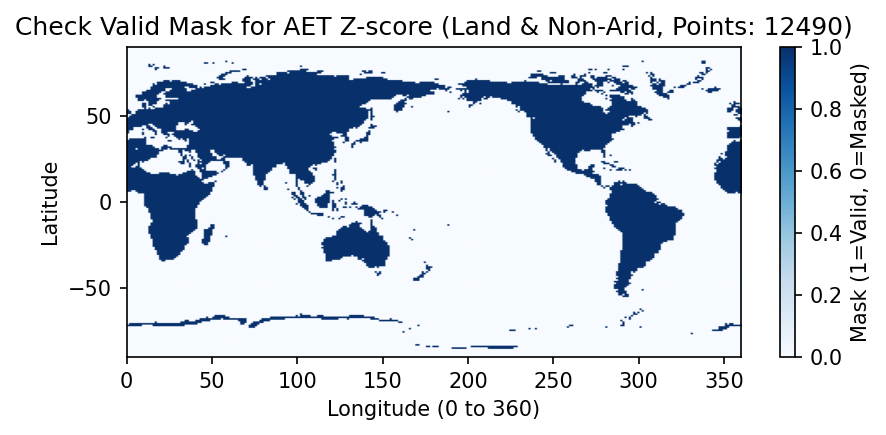

In [14]:
# AET 마스킹 격자 확인용 피규어

from global_land_mask import globe
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

ds_ssp = xr.open_dataset('AET_mean.nc', decode_times=False)

ssp_mean_grid = None
for v in ds_ssp.data_vars:
  arr = ds_ssp[v].squeeze()
  if arr.ndim == 2 and arr.shape == (192, 288):
    ssp_mean_grid = arr.values
    break
if ssp_mean_grid is None:
  ssp_mean_grid = ds_ssp[list(ds_ssp.data_vars)[0]].squeeze().values

lats = np.clip(ds_ssp['lat'].values, -90.0, 90.0)
lons = ds_ssp['lon'].values

lons_180 = np.where(lons > 180, lons - 360, lons)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)

is_land = globe.is_land(lat_grid, lon_grid)

# AET 기준 비활성 식생/사막/영구빙설 제외
is_active_et = ssp_mean_grid >= 0.15

valid_mask = is_land & is_active_et

plt.figure(figsize=(6, 3), dpi=150)
plt.imshow(
    valid_mask,
    origin='lower',
    extent=[0, 360, -90, 90],
    cmap='Blues',
    aspect='auto',
)
plt.title(f'Check Valid Mask for AET Z-score (Land & Non-Arid, Points: {np.sum(valid_mask)})')
plt.xlabel('Longitude (0 to 360)')
plt.ylabel('Latitude')
plt.colorbar(label='Mask (1=Valid, 0=Masked)')
plt.tight_layout()

plt.savefig('masking_check_aet.png', dpi=300)
plt.show()

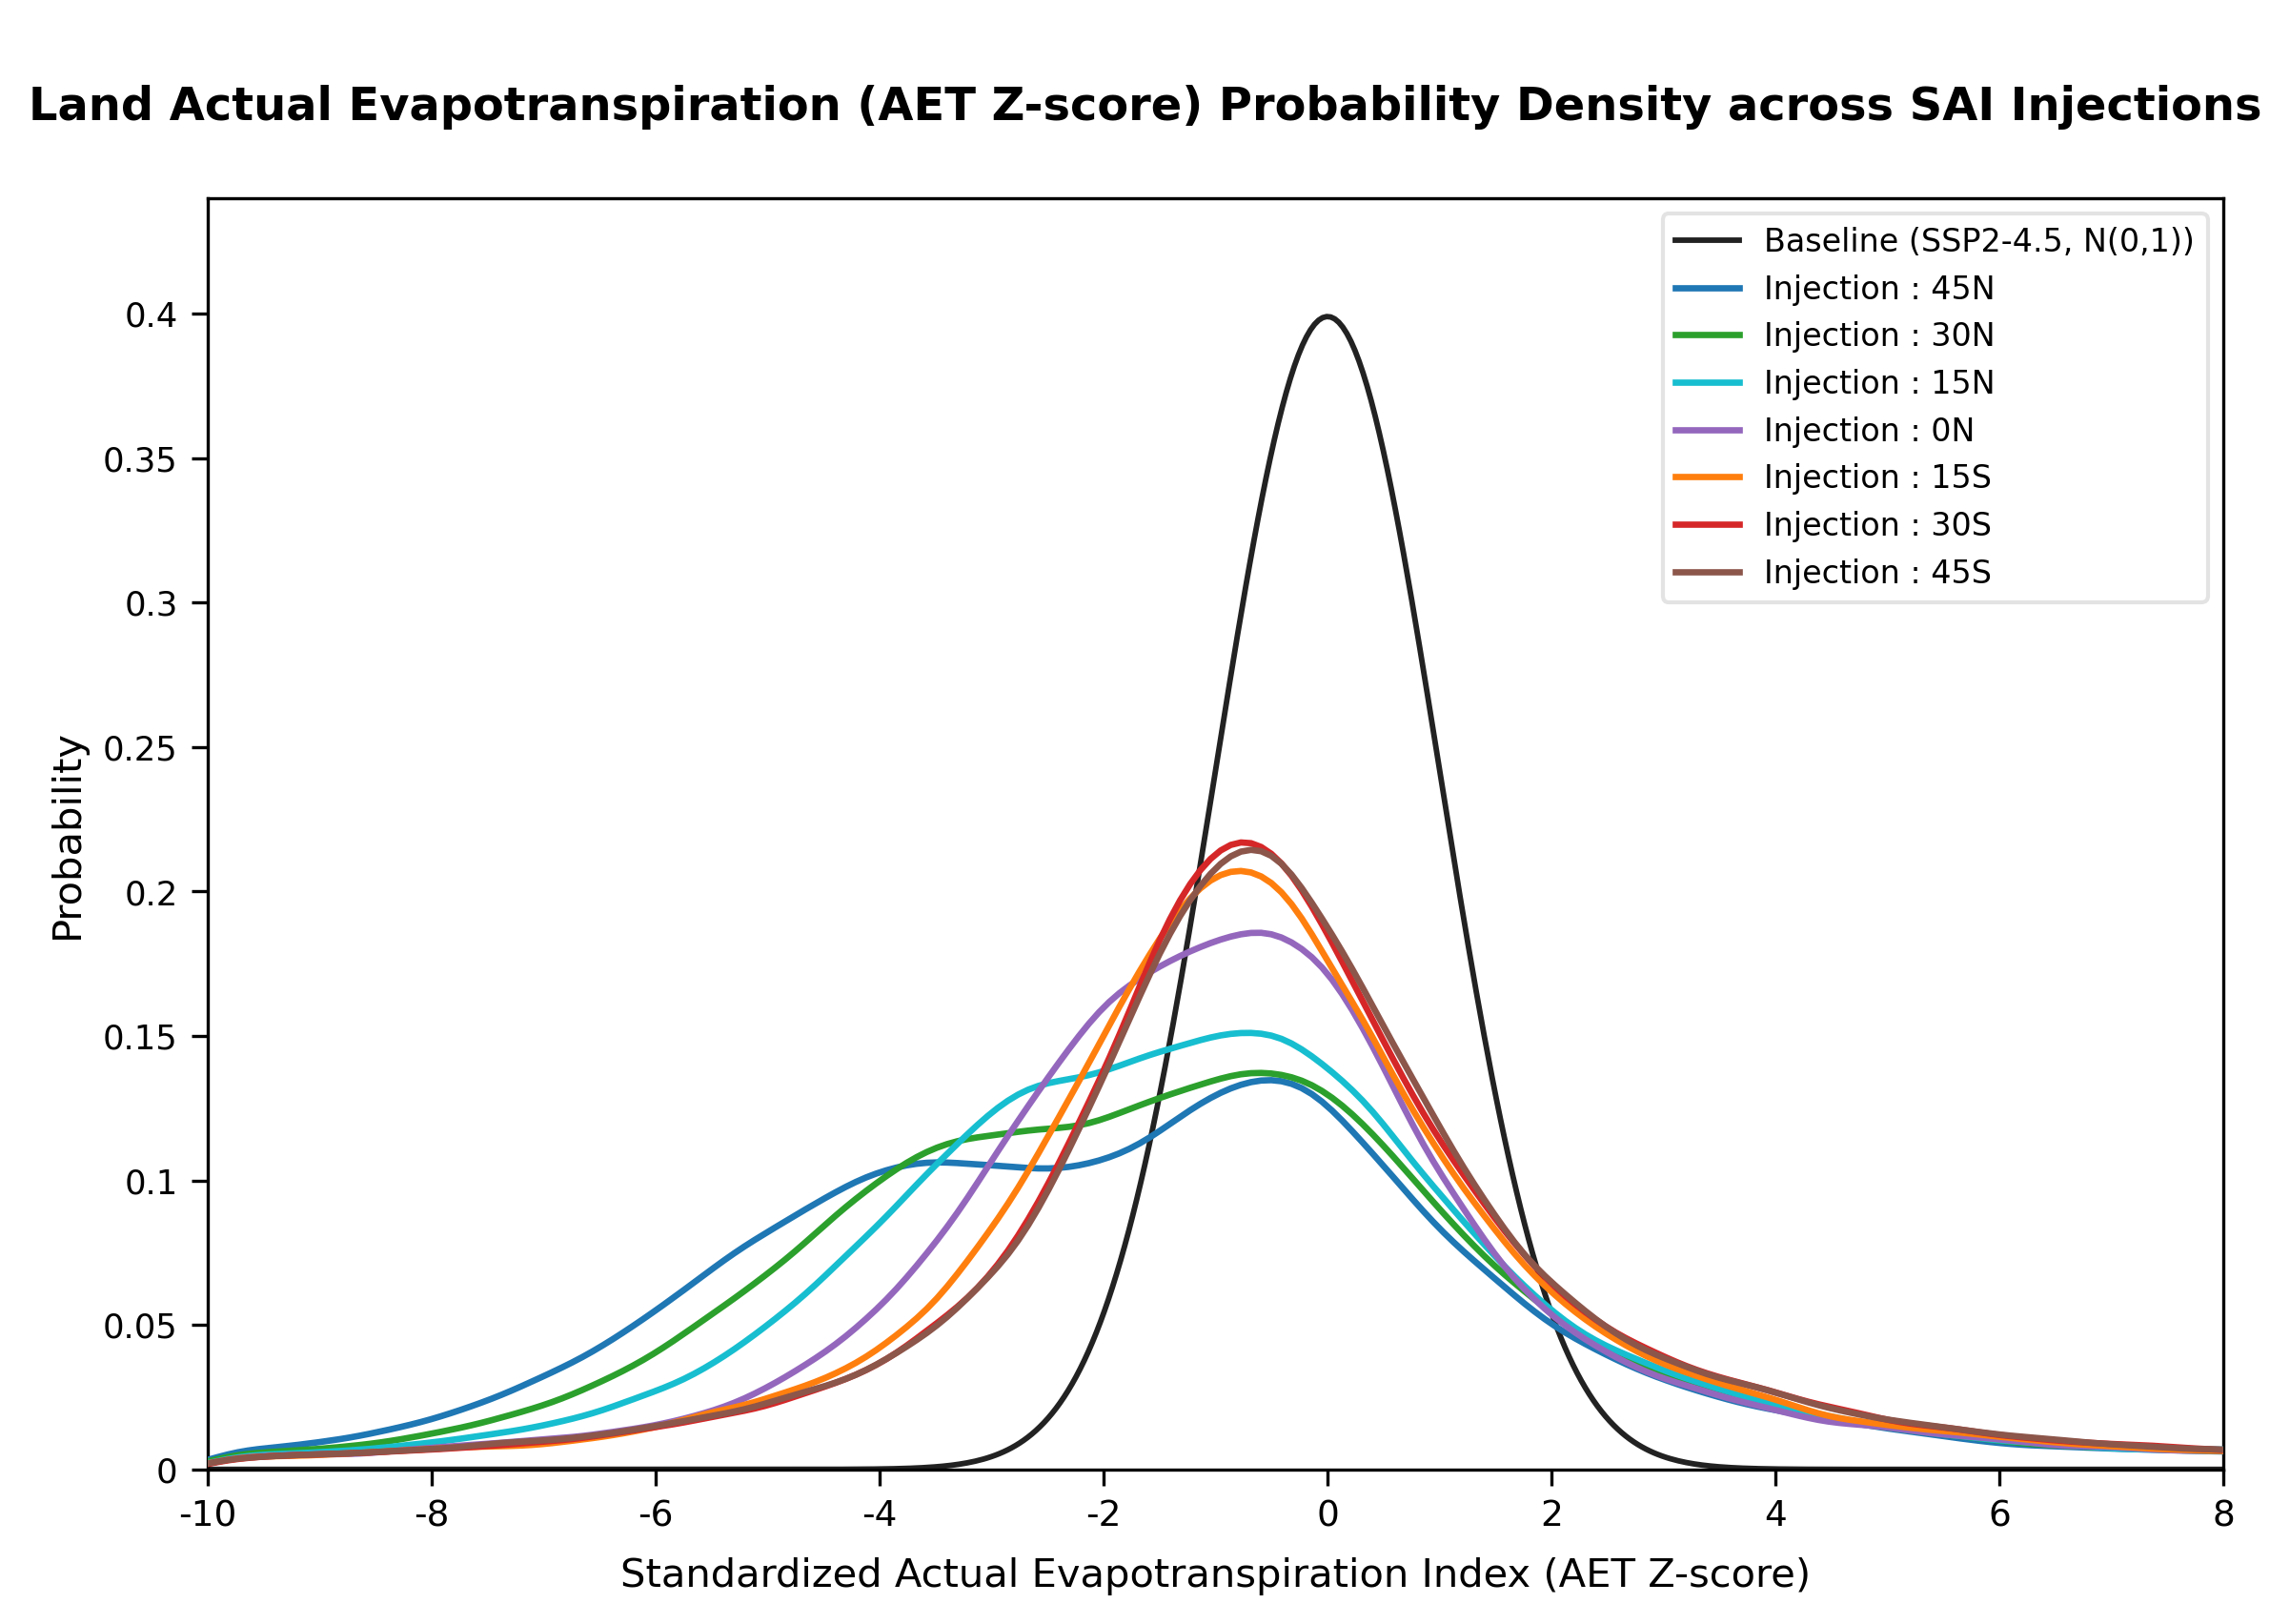

In [3]:
# AET PDF figure

from global_land_mask import globe
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import seaborn as sns
import xarray as xr


ds_ssp = xr.open_dataset('AET_mean.nc', decode_times=False)

ssp_mean_grid = None
for v in ds_ssp.data_vars:
  arr = ds_ssp[v].squeeze()
  if arr.ndim == 2 and arr.shape == (192, 288):
    ssp_mean_grid = arr.values
    break
if ssp_mean_grid is None:
  ssp_mean_grid = ds_ssp[list(ds_ssp.data_vars)[0]].squeeze().values

lons = ds_ssp['lon'].values
lats = np.clip(ds_ssp['lat'].values, -90.0, 90.0)

# 경도 변환
lons_180 = np.clip(np.where(lons > 180, lons - 360, lons), -180.0, 180.0)
lon_grid, lat_grid = np.meshgrid(lons_180, lats)

# 육상 마스크 & 비활성 식생/사막 제외
is_land = globe.is_land(lat_grid, lon_grid)
is_active_et = ssp_mean_grid >= 0.15
valid_mask = is_land & is_active_et



fig, (ax_bar, ax) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8.2, 5.6),
    dpi=300,
    gridspec_kw={'height_ratios': [0.10, 0.90], 'hspace': 0.04},
)

x_min, x_max = -10.0, 8.0

ax_bar.set_xlim(x_min, x_max)
ax_bar.set_ylim(0, 1)
ax_bar.axis('off')

#정규분포 곡선

x_axis = np.linspace(x_min, x_max, 500)
ax.plot(
    x_axis,
    norm.pdf(x_axis, 0, 1),
    color='#222222',
    linestyle='-',
    linewidth=1.4,
    label='Baseline (SSP2-4.5, N(0,1))',
    zorder=2,
)


scenarios = {
    '45N': 'AET_z-score_45N.nc',
    '30N': 'AET_z-score_30N.nc',
    '15N': 'AET_z-score_15N.nc',
    '0N': 'AET_z-score_0N.nc',
    '15S': 'AET_z-score_15S.nc',
    '30S': 'AET_z-score_30S.nc',
    '45S': 'AET_z-score_45S.nc',
}

palette = {
    '45N': '#1F77B4',
    '30N': '#2CA02C',
    '15N': '#17BECF',
    '0N': '#9467BD',
    '15S': '#FF7F0E',
    '30S': '#D62728',
    '45S': '#8C564B',
}

for label, file_path in scenarios.items():
  try:
    ds = xr.open_dataset(file_path, decode_times=False)
    z_var = [
        v
        for v in ds.data_vars
        if ds[v].ndim >= 2 and ds[v].shape[-2:] == (192, 288)
    ][0]
    z_data = ds[z_var].values

    valid_z = (
        z_data[:, valid_mask].flatten()
        if z_data.ndim == 3
        else z_data[valid_mask].flatten()
    )
    valid_z = valid_z[np.isfinite(valid_z)]
    valid_z = valid_z[(valid_z >= -10.0) & (valid_z <= 10.0)]

    mean_val_scen = np.mean(valid_z)
    scen_color = palette.get(label, '#333333')

    
    sns.kdeplot(
        valid_z,
        ax=ax,
        color=scen_color,
        linewidth=1.6,
        clip=(x_min, x_max),
        label=f'Injection : {label}',
        zorder=3,
    )
  except FileNotFoundError:
    print(f'[{label}] 파일 없음: {file_path}')
  except Exception as e:
    print(f'[{label}] 오류 발생: {e}')

#하단 축
ax.set_xlim(x_min, x_max)
ax.set_ylim(0, 0.44)
ax.set_xticks([-10, -8, -6, -4, -2, 0, 2, 4, 6, 8])
ax.set_xticklabels(
    ['-10', '-8', '-6', '-4', '-2', '0', '2', '4', '6', '8'],
    fontsize=9,
)
ax.set_xlabel(
    'Standardized Actual Evapotranspiration Index (AET Z-score)',
    fontsize=10,
    labelpad=6,
)

ax.set_yticks(np.arange(0, 0.45, 0.05))
ax.set_yticklabels(
    ['0', '0.05', '0.1', '0.15', '0.2', '0.25', '0.3', '0.35', '0.4'],
    fontsize=8.5,
)
ax.set_ylabel('Probability', fontsize=10)

ax.tick_params(direction='out', length=4, width=0.8, top=False, right=False)
for spine in ax.spines.values():
  spine.set_linewidth(0.8)

ax.legend(frameon=True, fontsize=8, loc='upper right', edgecolor='#DDDDDD')

# 전체 상단 메인 타이틀
fig.suptitle(
    'Land Actual Evapotranspiration (AET Z-score) Probability Density across'
    ' SAI Injections',
    fontsize=11.5,
    fontweight='bold',
    y=0.965,
)

# 여백 조정 (SPI와 동일한 비율)
plt.subplots_adjust(left=0.10, right=0.96, top=1.0, bottom=0.10)

plt.savefig('aet_pdf_30y.png', dpi=300)
plt.show()